In [ ]:

import heapq

print("Required library imported successfully.")


Required library imported successfully.


In [ ]:

# Define the graph with weighted edges
graph = {
    'A': {'B': 4, 'C': 3},
    'B': {'D': 5, 'E': 2},
    'C': {'F': 7},
    'D': {'G': 2},
    'E': {'G': 3},
    'F': {'G': 2},
    'G': {}
}

# Define heuristic values (estimated cost to goal G)
heuristic = {
    'A': 7,
    'B': 5,
    'C': 6,
    'D': 2,
    'E': 3,
    'F': 2,
    'G': 0
}

print("Graph representation:")
for node, neighbors in graph.items():
    print(f"{node} -> {neighbors}")

print("\nHeuristic values:")
for node, value in heuristic.items():
    print(f"h({node}) = {value}")


Graph representation:
A -> {'B': 4, 'C': 3}
B -> {'D': 5, 'E': 2}
C -> {'F': 7}
D -> {'G': 2}
E -> {'G': 3}
F -> {'G': 2}
G -> {}

Heuristic values:
h(A) = 7
h(B) = 5
h(C) = 6
h(D) = 2
h(E) = 3
h(F) = 2
h(G) = 0


In [ ]:

def a_star_search(graph, heuristic, start, goal):
    # Initialize priority queue: (f_cost, g_cost, node, path)
    priority_queue = [(heuristic[start], 0, start, [start])]

    # Store the lowest known cost to reach each node
    best_cost = {start: 0}

    while priority_queue:
        f_cost, g_cost, current, path = heapq.heappop(priority_queue)

        # Skip outdated entries
        if g_cost > best_cost.get(current, float("inf")):
            continue

        # If destination is reached, return path and cost
        if current == goal:
            return path, g_cost

        # Explore neighboring nodes
        for neighbor, edge_cost in graph[current].items():
            new_cost = g_cost + edge_cost

            if new_cost < best_cost.get(neighbor, float("inf")):
                best_cost[neighbor] = new_cost
                f_new = new_cost + heuristic[neighbor]

                heapq.heappush(
                    priority_queue,
                    (f_new, new_cost, neighbor, path + [neighbor])
                )

    return None, float("inf")


print("A* Search function defined successfully.")


A* Search function defined successfully.


In [ ]:

# Define the source and destination
start_node = 'A'
goal_node = 'G'

# Run the A* Search Algorithm
path, total_cost = a_star_search(
    graph, heuristic, start_node, goal_node
)

# Display the result
print("Source Node:", start_node)
print("Destination Node:", goal_node)

if path:
    print("Shortest Path:", " -> ".join(path))
    print("Total Path Cost:", total_cost)
else:
    print("No path exists between the source and destination.")


Source Node: A
Destination Node: G
Shortest Path: A -> B -> E -> G
Total Path Cost: 9


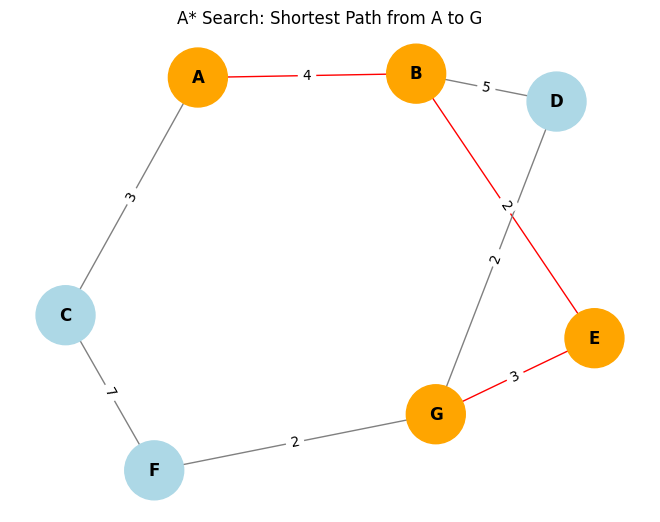

In [ ]:

import networkx as nx
import matplotlib.pyplot as plt

# Create a graph for visualization
G = nx.Graph()

# Add edges and their costs
for node, neighbors in graph.items():
    for neighbor, cost in neighbors.items():
        G.add_edge(node, neighbor, weight=cost)

# Arrange nodes for a clear display
pos = nx.spring_layout(G, seed=42)

# Highlight the shortest path
path_edges = list(zip(path, path[1:]))

node_colors = [
    "orange" if node in path else "lightblue"
    for node in G.nodes()
]

edge_colors = [
    "red" if edge in path_edges or (edge[1], edge[0]) in path_edges
    else "gray"
    for edge in G.edges()
]

# Draw graph
nx.draw(
    G, pos, with_labels=True,
    node_color=node_colors,
    edge_color=edge_colors,
    node_size=1800,
    font_size=12,
    font_weight="bold"
)

# Display edge costs
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("A* Search: Shortest Path from A to G")
plt.show()
